# Biography databases

Scholarly biographical dictionaries Cultura can be compared with: one biography downloaded from each (`building_scripts/dictionary_texts.py`).

In [1]:
import json
import sys
from pathlib import Path

import duckdb
import polars as pl

ROOT = Path.cwd().resolve()
while not (ROOT / ".git").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts" / "5-annotations" / "building_scripts"))
from dictionary_texts import DB, DICTIONARIES, OUT

sys.path.insert(0, str(ROOT / "notebooks" / "notebooks_analysis"))
from style import show_table

texts = json.loads(OUT.read_text(encoding="utf-8"))
downloaded = {key: row for key, row in texts.items() if "text" in row and "pid" in DICTIONARIES[key]}
treccani = pl.read_parquet(ROOT / "scripts" / "5-annotations" / "legacy" / "treccani_validation" / "treccani_texts.parquet")
labels = pl.DataFrame(duckdb.connect(str(DB), read_only=True).execute(
    "SELECT entity.qid AS wikidata_id, entity.label_en AS label FROM individual WHERE entity.qid IN (SELECT unnest(?)) AND entity.label_en IS NOT NULL",
    [treccani["wikidata_id"].to_list()]).fetchall(), schema=["wikidata_id", "label"], orient="row")
treccani_example = treccani.join(labels, on="wikidata_id").sort("wikidata_id").sample(1, seed=42).row(0, named=True)
example_qids = [row["qid"] for row in downloaded.values()] + [treccani_example["wikidata_id"]]
ENRICHED_DB = ROOT / "data" / "cultura" / "cultura_enriched_v3.2.duckdb"


def year(value, source):
    return f"c. {value}" if source == "estimated" else str(value)


lifespans = {qid: f"({year(birth, birth_source)}–{year(death, death_source)})" for qid, birth, birth_source, death, death_source in duckdb.connect(str(ENRICHED_DB), read_only=True).execute(
    "SELECT entity.qid, birth_date.year, birth_date.source, death_date.year, death_date.source FROM individual_enriched WHERE entity.qid IN (SELECT unnest(?))",
    [example_qids]).fetchall()}
print(f"Treccani example: {treccani_example['label']} ({treccani_example['wikidata_id']}), {treccani_example['dbi_url']}")
print(f"{len(DICTIONARIES)} dictionaries, {len(downloaded)} with a downloaded biography and a Wikidata identifier")

Treccani example: Anselm, Duke of Friuli (Q569615), https://www.treccani.it/enciclopedia/anselmo-di-nonantola-santo_(Dizionario-Biografico)/
21 dictionaries, 12 with a downloaded biography and a Wikidata identifier


## Overview table

In [2]:
REGIONS = {
    "treccani": "Italy",
    "deutsche_biographie": "German-speaking world", "oebl": "Austria-Hungary", "dwb": "Wales", "sbl": "Sweden",
    "nbl": "Norway", "dbl": "Denmark", "dcb": "Canada", "iranica": "Persia, Islamic East", "encykorea": "Korea",
    "sep": "Global / Philosophers", "mactutor": "Global / Mathematicians", "catholic_encyclopedia": "Global / Catholic Church",
}

overview = pl.DataFrame([
    {
        "Dictionary": DICTIONARIES[key]["name"],
        "Region / Topic": REGIONS[key],
        "Biography Example": f'{row["label"]} {lifespans[row["qid"]]}',
        "Number of Characters": len(row["text"]),
    }
    for key, row in downloaded.items()
] + [{
    "Dictionary": "Dizionario Biografico degli Italiani (Treccani)",
    "Region / Topic": REGIONS["treccani"],
    "Biography Example": f'{treccani_example["label"]} {lifespans[treccani_example["wikidata_id"]]}',
    "Number of Characters": len(treccani_example["text"]),
}]).sort("Dictionary")
assert overview["Dictionary"].is_unique().all() and overview["Biography Example"].null_count() == 0
overview.shape

(13, 4)

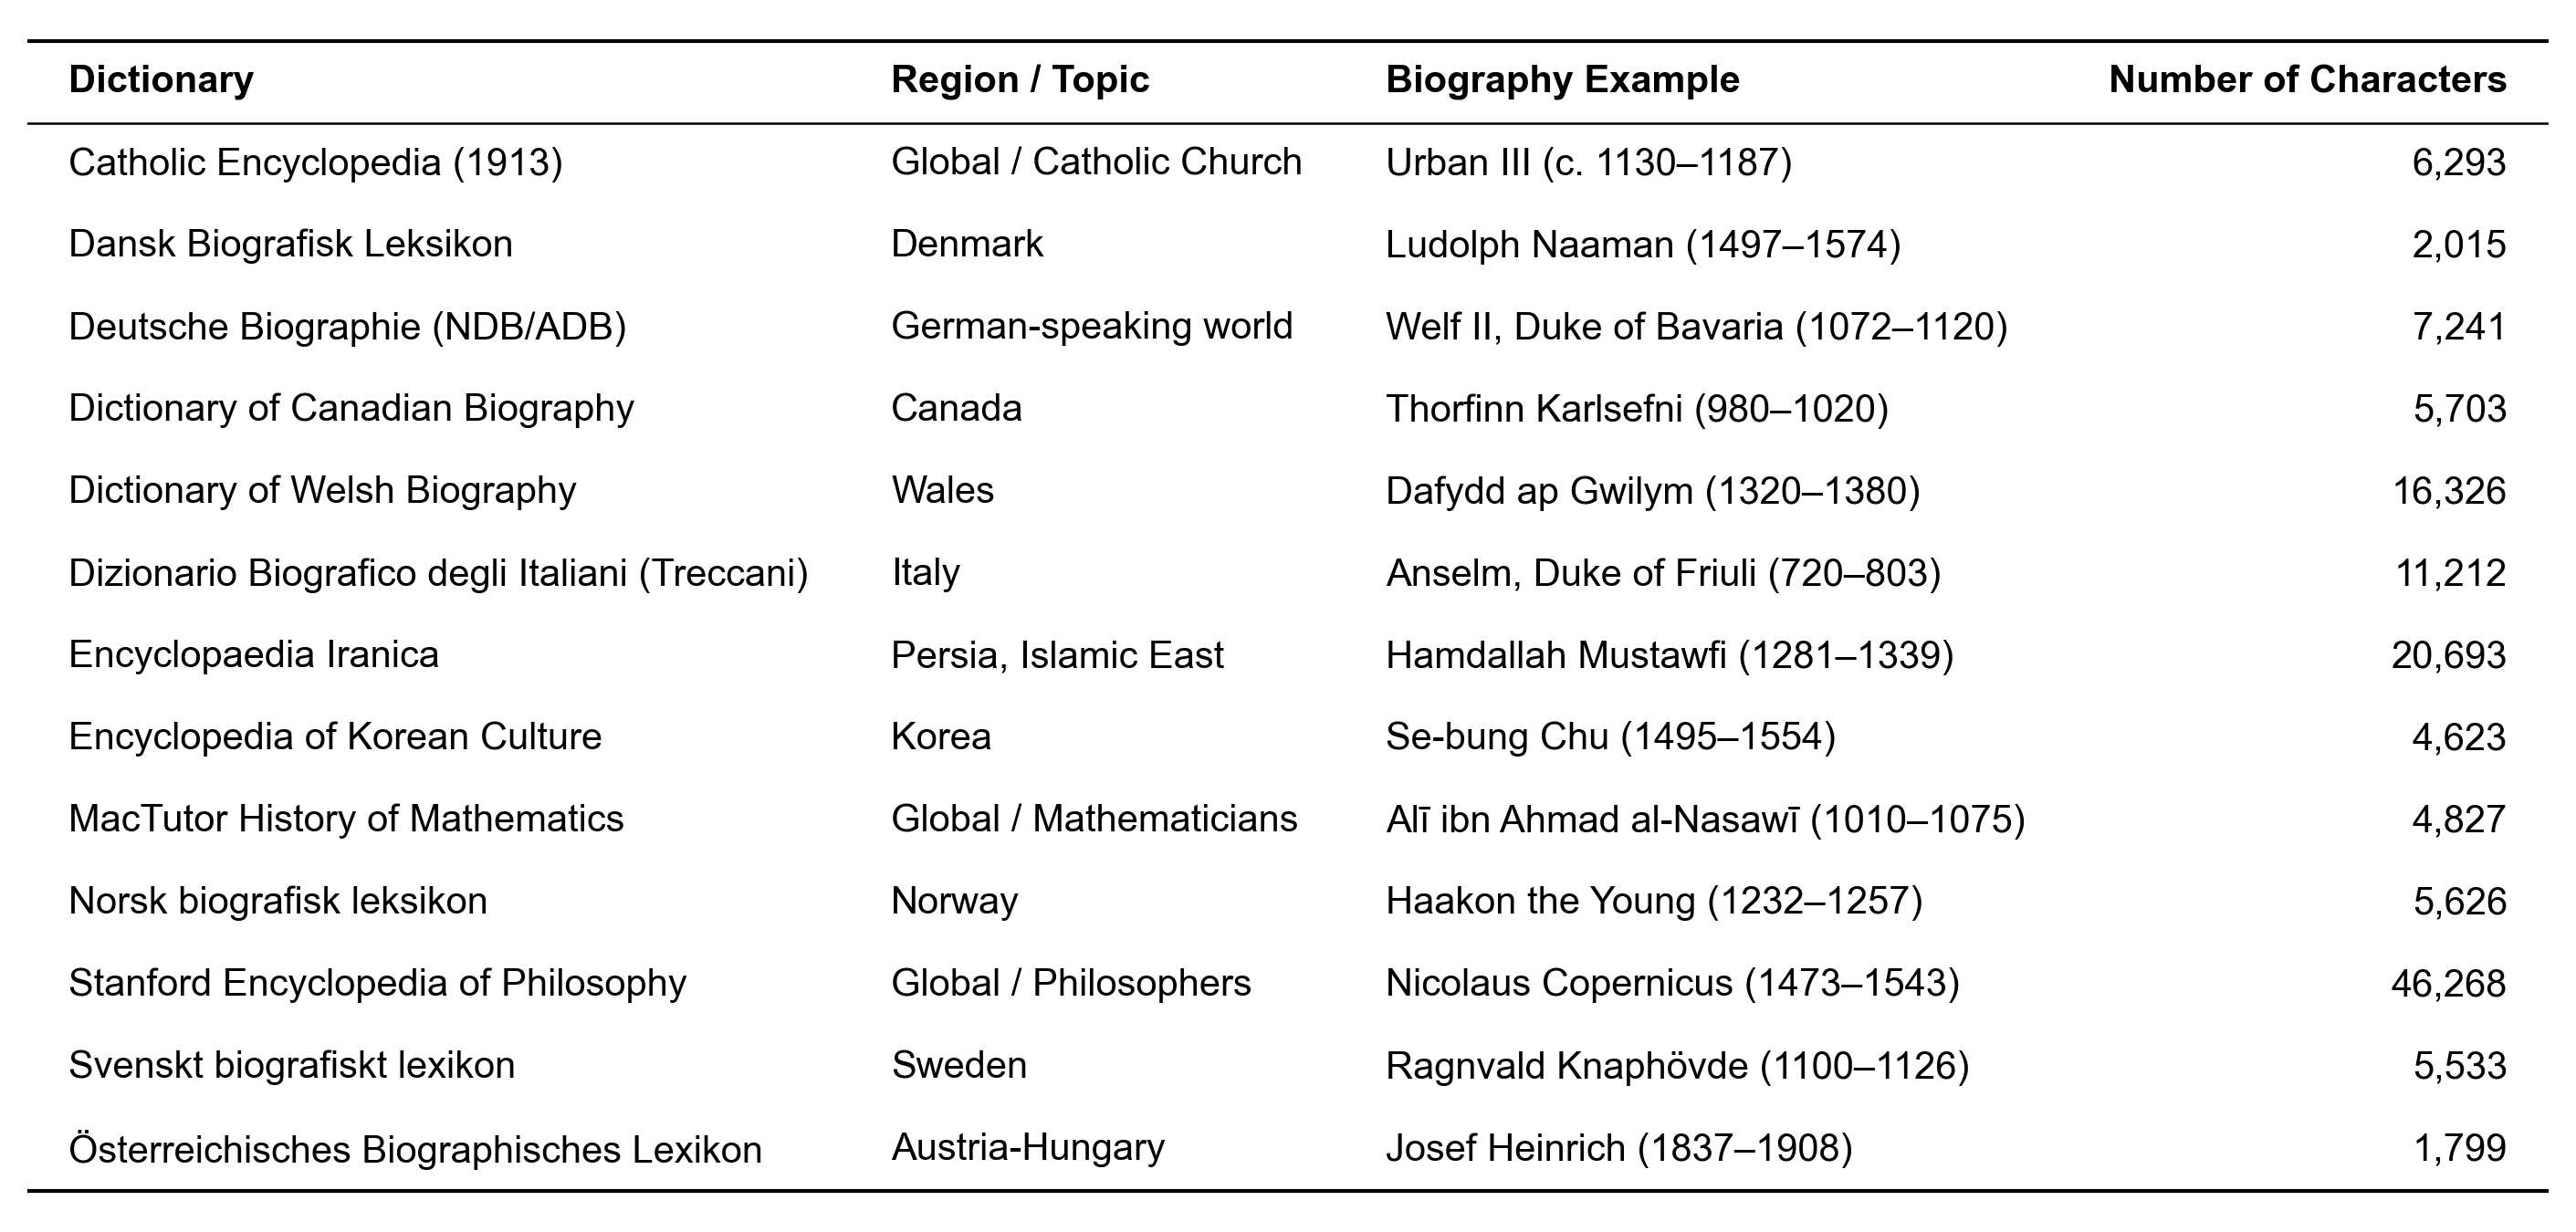

In [3]:
show_table(overview, font_size=10)

## Benchmark coverage

Cultura individuals covered by at least one dictionary, with an English label, a birth and a death year (`building_scripts/benchmark_population.py`). Region from the birthplace, else the country of citizenship, in present-day borders; century of birth.

In [4]:
population = pl.read_parquet(ROOT / "scripts" / "5-annotations" / "benchmark" / "benchmark_population.parquet")
NAMES = {key: dictionary["name"] for key, dictionary in DICTIONARIES.items()} | {"treccani": "Dizionario Biografico degli Italiani (Treccani)"}
PERIODS = [(-10_000, 500, "before 500"), (500, 1000, "500–999"), (1000, 1300, "1000–1299"), (1300, 1500, "1300–1499"),
           (1500, 1600, "1500s"), (1600, 1700, "1600s"), (1700, 1800, "1700s"), (1800, 1900, "1800s"), (1900, 3000, "1900s")]
REGION_ORDER = ["Western Europe", "Northern Europe", "Southern Europe", "Eastern Europe", "Middle East & North Africa",
                "South & Central Asia", "East Asia", "Southeast Asia", "Sub-Saharan Africa", "North America",
                "Latin America", "Oceania", "Other", "Unknown"]

period = pl.lit(None, dtype=pl.Utf8)
for low, high, label in reversed(PERIODS):
    period = pl.when((pl.col("birth_year") >= low) & (pl.col("birth_year") < high)).then(pl.lit(label)).otherwise(period)
people = population.unique("qid").with_columns(period=period)
assert people["period"].null_count() == 0
print(f"{len(population):,} dictionary entries, {len(people):,} individuals")

114,763 dictionary entries, 109,452 individuals


### Individuals per dictionary

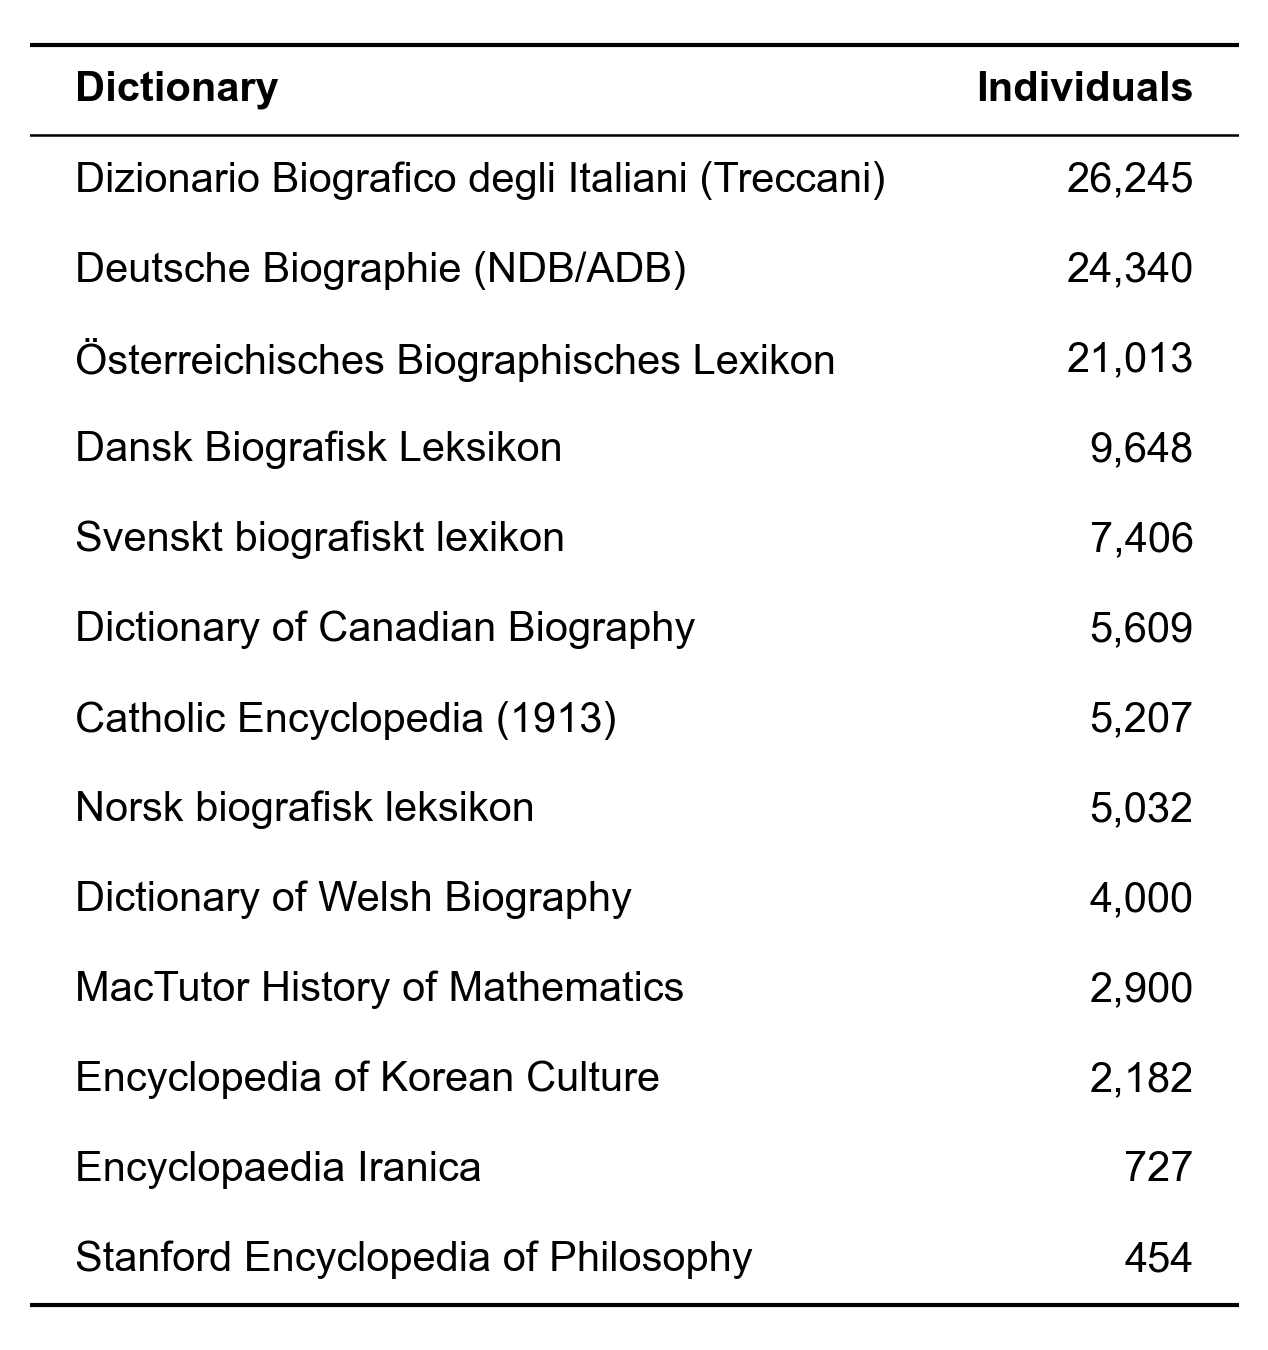

In [5]:
per_dictionary = (population.group_by("dictionary").agg(pl.col("qid").n_unique().alias("Individuals"))
    .with_columns(pl.col("dictionary").replace_strict(NAMES).alias("Dictionary"))
    .select("Dictionary", "Individuals").sort("Individuals", descending=True))
show_table(per_dictionary, font_size=10)

### Individuals per region and period of birth

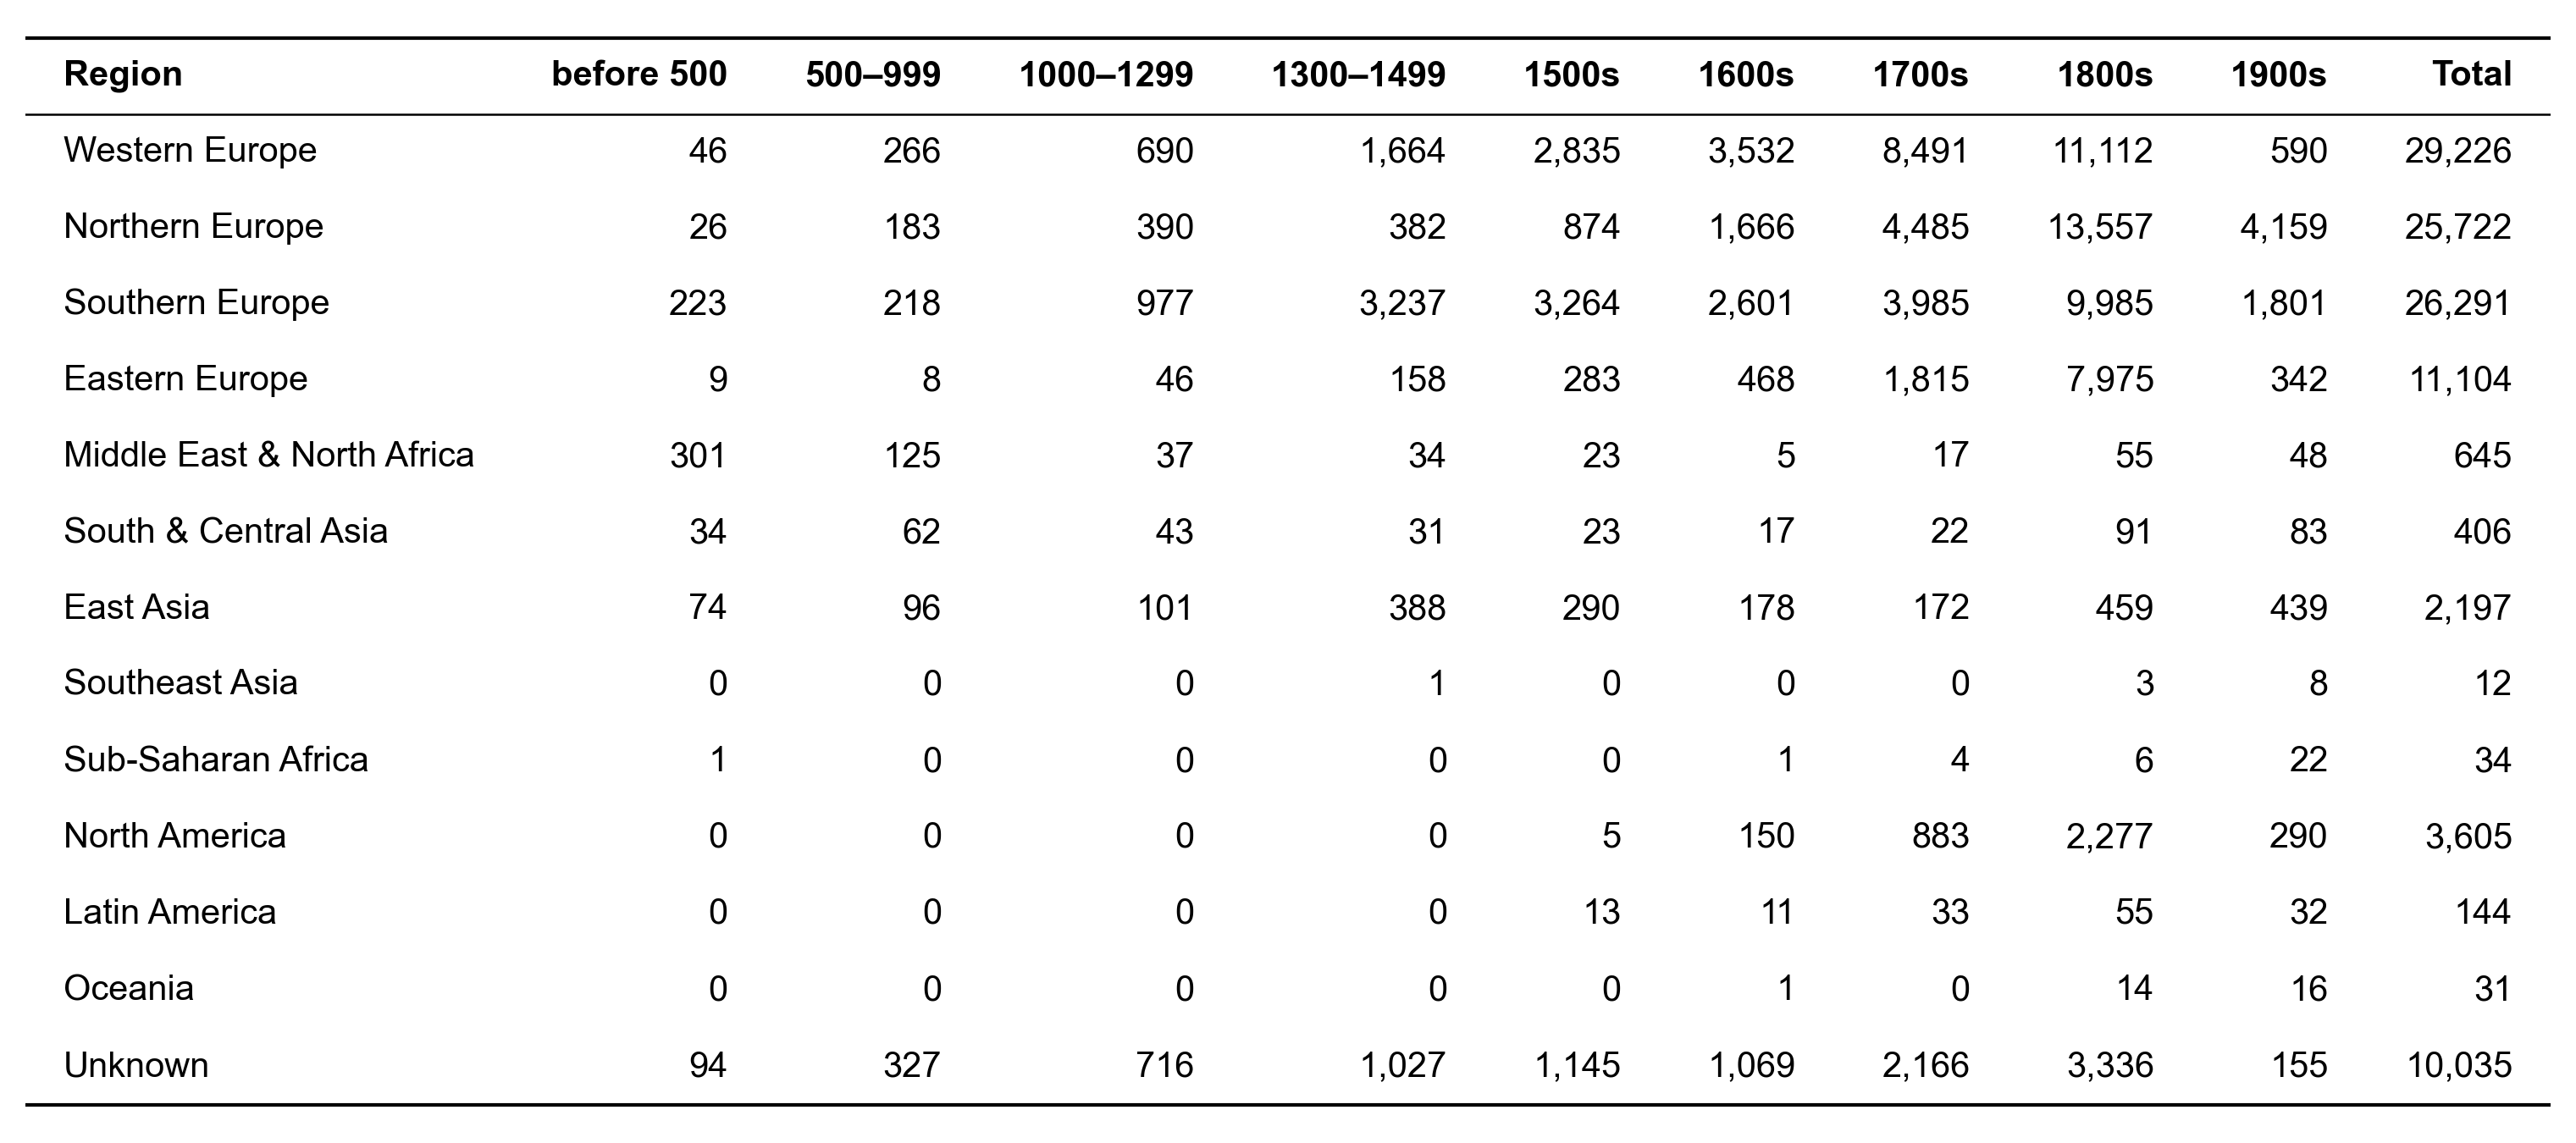

In [6]:
labels = [label for _, _, label in PERIODS]
per_region = (people.pivot(on="period", index="region", values="qid", aggregate_function="len")
    .with_columns(pl.col("region").replace_strict({r: i for i, r in enumerate(REGION_ORDER)}).alias("order"))
    .sort("order").fill_null(0))
per_region = per_region.select(pl.col("region").alias("Region"), *[pl.col(label) for label in labels if label in per_region.columns]).with_columns(
    Total=pl.sum_horizontal(*[pl.col(label) for label in labels if label in per_region.columns]))
show_table(per_region, font_size=10)

## Benchmark of 300 individuals

Drawn by `building_scripts/benchmark_sample.py`: a quota per region, spread over the periods of birth and the dictionaries of each region. Only individuals with the three Cultura life stages (early, active and late), each with its years, dated or estimated, enter the benchmark. Each region's quota is split in half between two notability levels, from the number of Wikipedia editions with an article on the individual: famous (10 editions or more) and less known (fewer than 10).

In [7]:
sample = pl.read_parquet(ROOT / "scripts" / "5-annotations" / "benchmark" / "benchmark_sample.parquet")
benchmark = sample.filter(pl.col("in_benchmark"))
assert len(benchmark) == 300 and benchmark["qid"].is_unique().all()
SHORT = {"Western Europe": "W. Europe", "Northern Europe": "N. Europe", "Southern Europe": "S. Europe", "Eastern Europe": "E. Europe",
         "Middle East & North Africa": "MENA", "South & Central Asia": "S. & C. Asia", "East Asia": "E. Asia",
         "North America": "N. America", "Latin America": "Lat. America", "Sub-Saharan Africa": "SS Africa", "Oceania": "Oceania"}
regions = [region for region in REGION_ORDER if region in benchmark["region"].unique().to_list()]
benchmark.head()

dictionary,qid,dictionary_id,label,birth_year,death_year,latitude,longitude,located_by,country,region,century,period,wikipedia_editions,notability,rank,three_stages,in_benchmark
str,str,str,str,i64,i64,f64,f64,str,str,str,i64,str,i64,str,i64,bool,bool
"""catholic_encyclopedia""","""Q169288""","""08018b""","""Innocent VI""",1282,1362,45.371389,1.403889,"""birthplace""","""France""","""Western Europe""",13,"""1000–1299""",73,"""famous""",0,true,true
"""sbl""","""Q61873""","""17601""","""Dorothea of Brandenburg""",1430,1495,52.414139,12.554083,"""birthplace""","""Germany""","""Western Europe""",15,"""1300–1499""",32,"""famous""",1,true,true
"""sep""","""Q190944""","""bodin""","""Jean Bodin""",1530,1596,47.472778,-0.555555,"""birthplace""","""France""","""Western Europe""",16,"""1500s""",53,"""famous""",2,true,true
"""dcb""","""Q3384708""","""denys_de_la_ronde_pierre_2""","""Pierre Denys de La Ronde""",1631,1708,47.392778,0.688333,"""birthplace""","""France""","""Western Europe""",17,"""1600s""",1,"""less known""",3,true,true
"""iranica""","""Q1378109""","""jaubert-pierre""","""Pierre Amédée Jaubert""",1779,1847,43.527778,5.445556,"""birthplace""","""France""","""Western Europe""",18,"""1700s""",14,"""famous""",4,true,true


### Benchmark individuals per dictionary and region

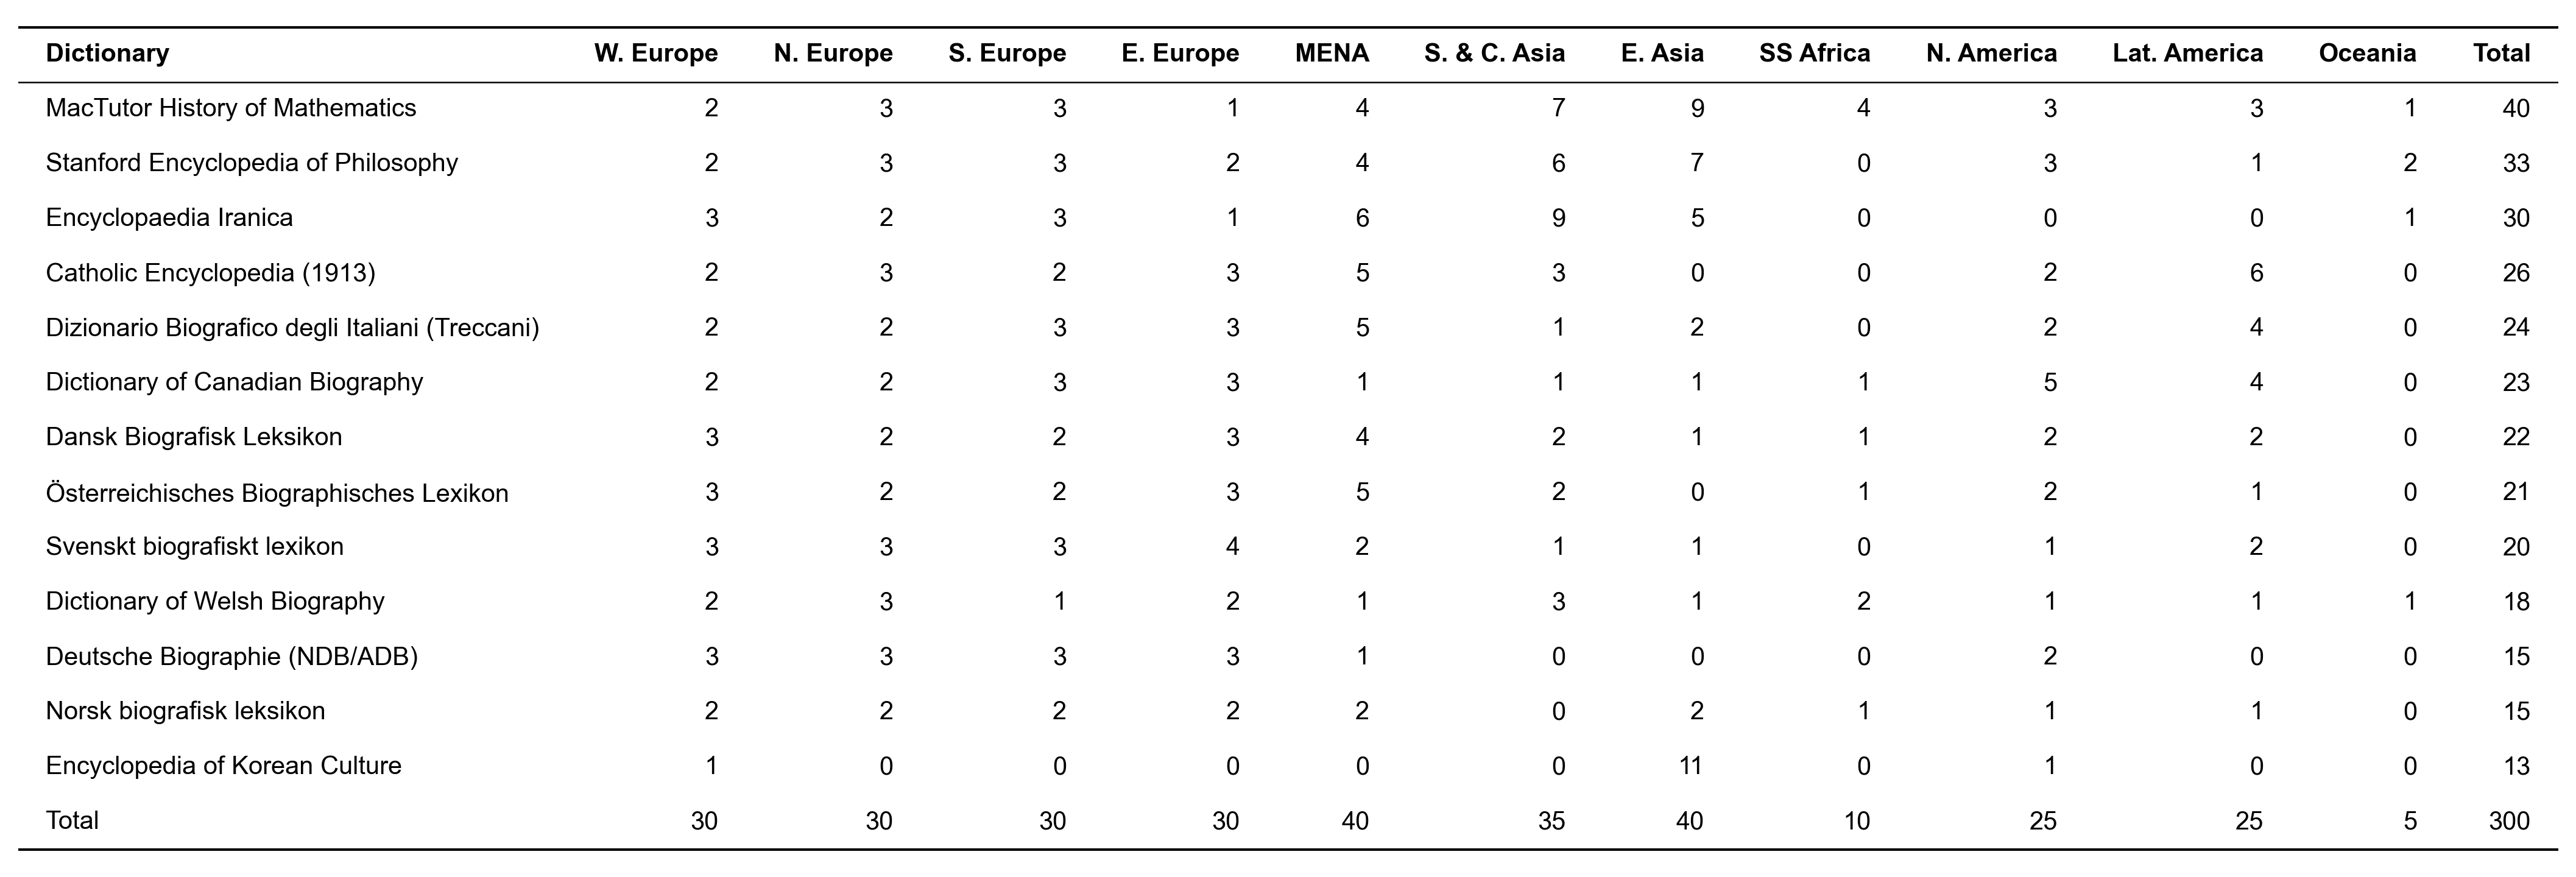

In [8]:
per_dictionary_region = (benchmark.pivot(on="region", index="dictionary", values="qid", aggregate_function="len").fill_null(0)
    .with_columns(pl.col("dictionary").replace_strict(NAMES).alias("Dictionary"))
    .select("Dictionary", *[pl.col(region).alias(SHORT[region]) for region in regions]))
per_dictionary_region = per_dictionary_region.with_columns(Total=pl.sum_horizontal(*[SHORT[region] for region in regions])).sort("Total", descending=True)
totals = pl.DataFrame([{"Dictionary": "Total", **{c: per_dictionary_region[c].sum() for c in per_dictionary_region.columns[1:]}}])
show_table(pl.concat([per_dictionary_region, totals], how="vertical_relaxed"), font_size=10)

### Benchmark individuals per region and period of birth

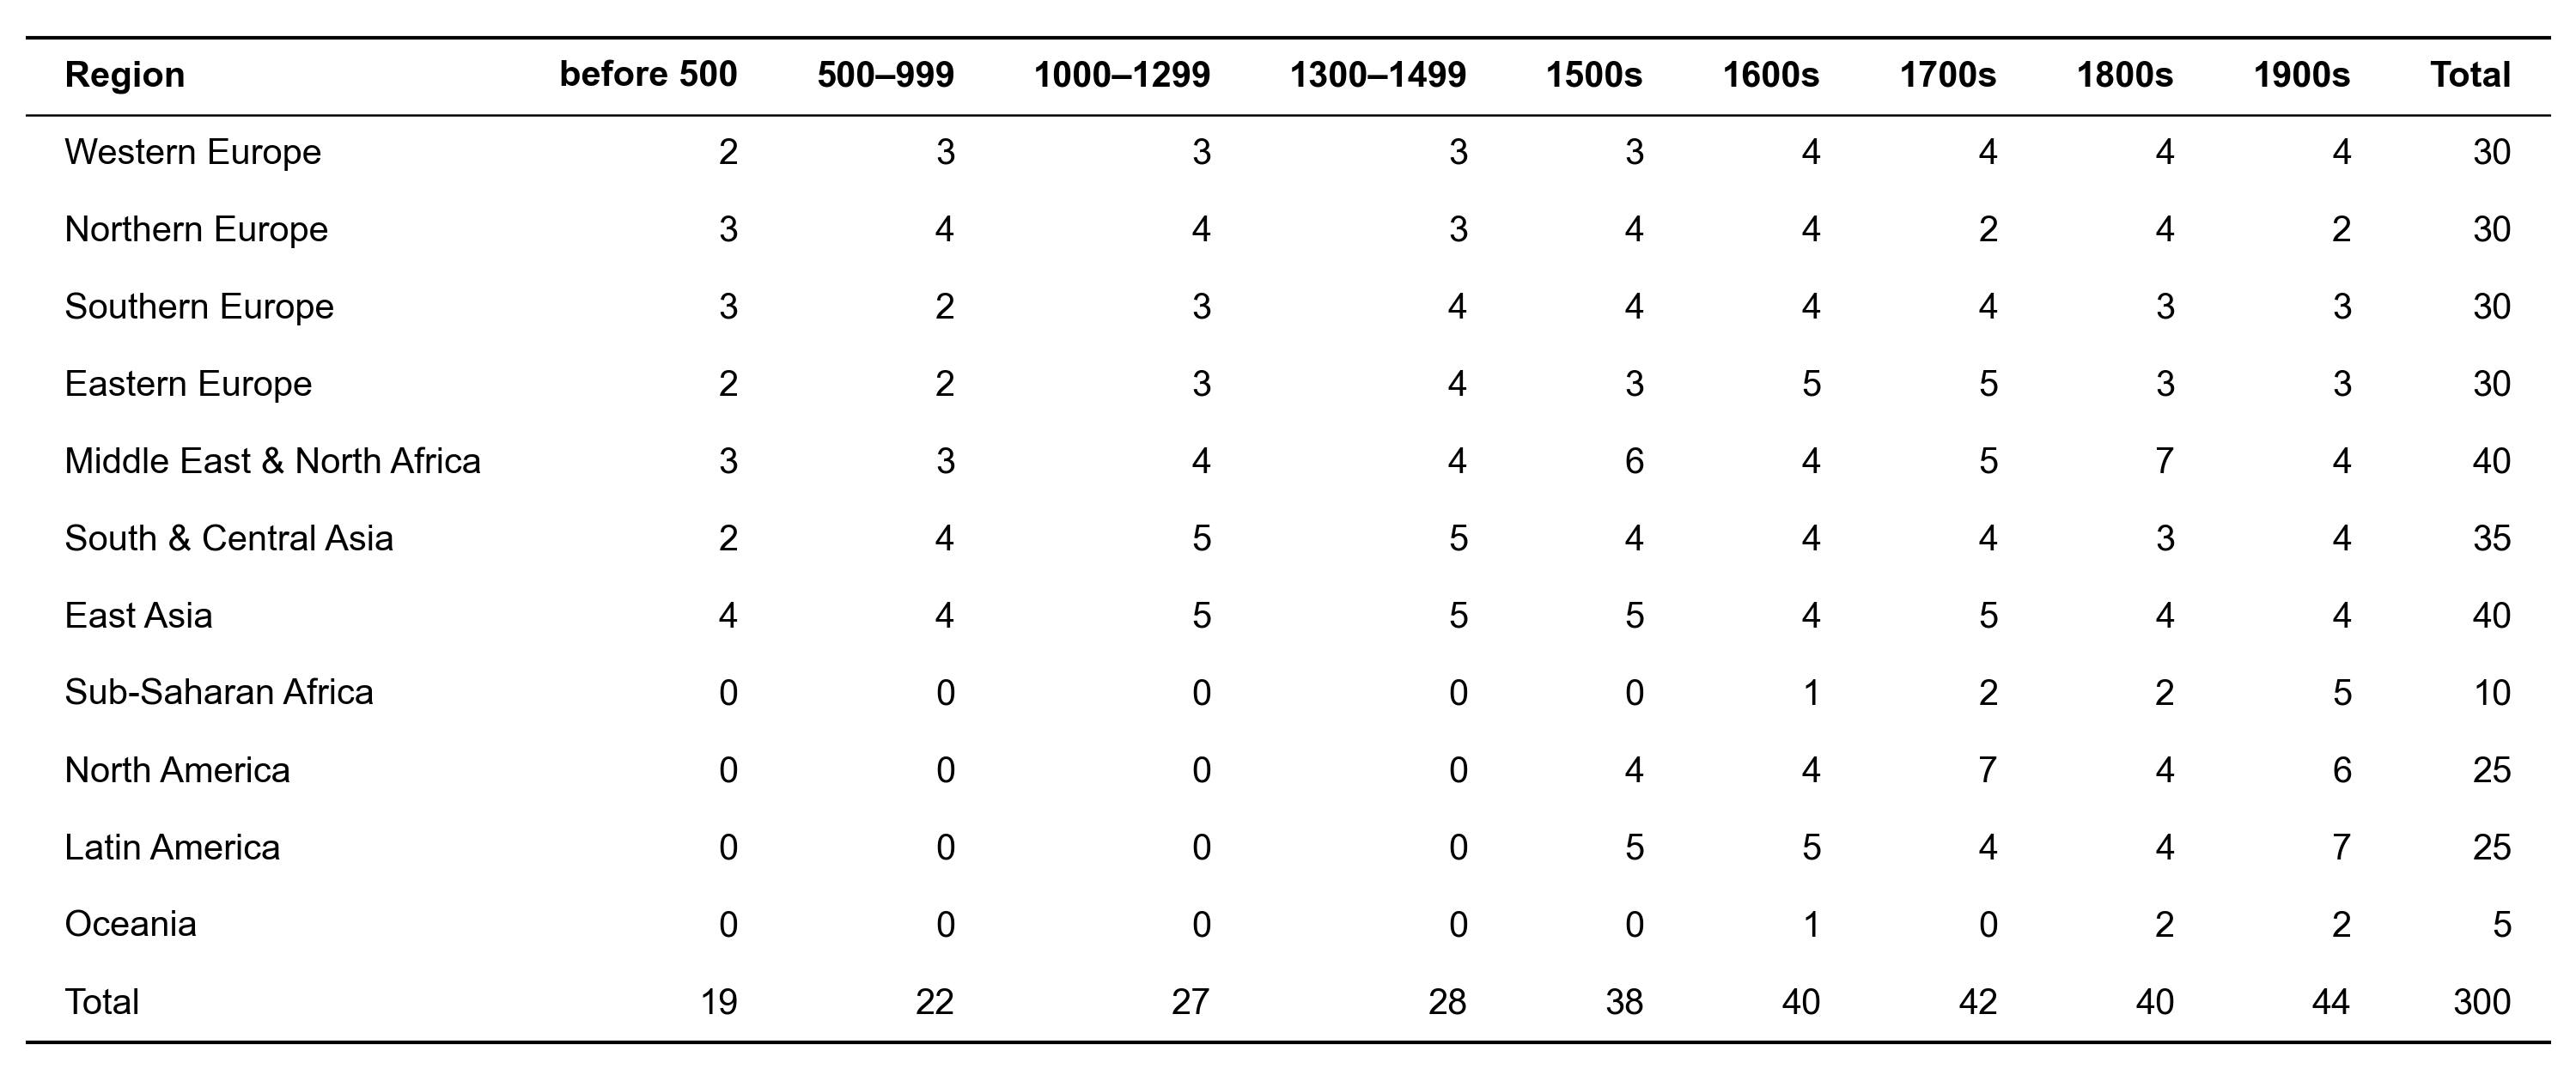

In [9]:
benchmark_region = (benchmark.pivot(on="period", index="region", values="qid", aggregate_function="len")
    .with_columns(pl.col("region").replace_strict({r: i for i, r in enumerate(REGION_ORDER)}).alias("order"))
    .sort("order").fill_null(0))
present = [label for label in labels if label in benchmark_region.columns]
benchmark_region = benchmark_region.select(pl.col("region").alias("Region"), *present).with_columns(Total=pl.sum_horizontal(*present))
totals = pl.DataFrame([{"Region": "Total", **{c: benchmark_region[c].sum() for c in benchmark_region.columns[1:]}}])
show_table(pl.concat([benchmark_region, totals], how="vertical_relaxed"), font_size=10)

### Benchmark individuals per region and notability

Famous: 10 Wikipedia editions or more; less known: fewer than 10. Candidates are the individuals of the region with the three Cultura life stages. A region short of famous candidates (Sub-Saharan Africa) is completed with less known individuals.

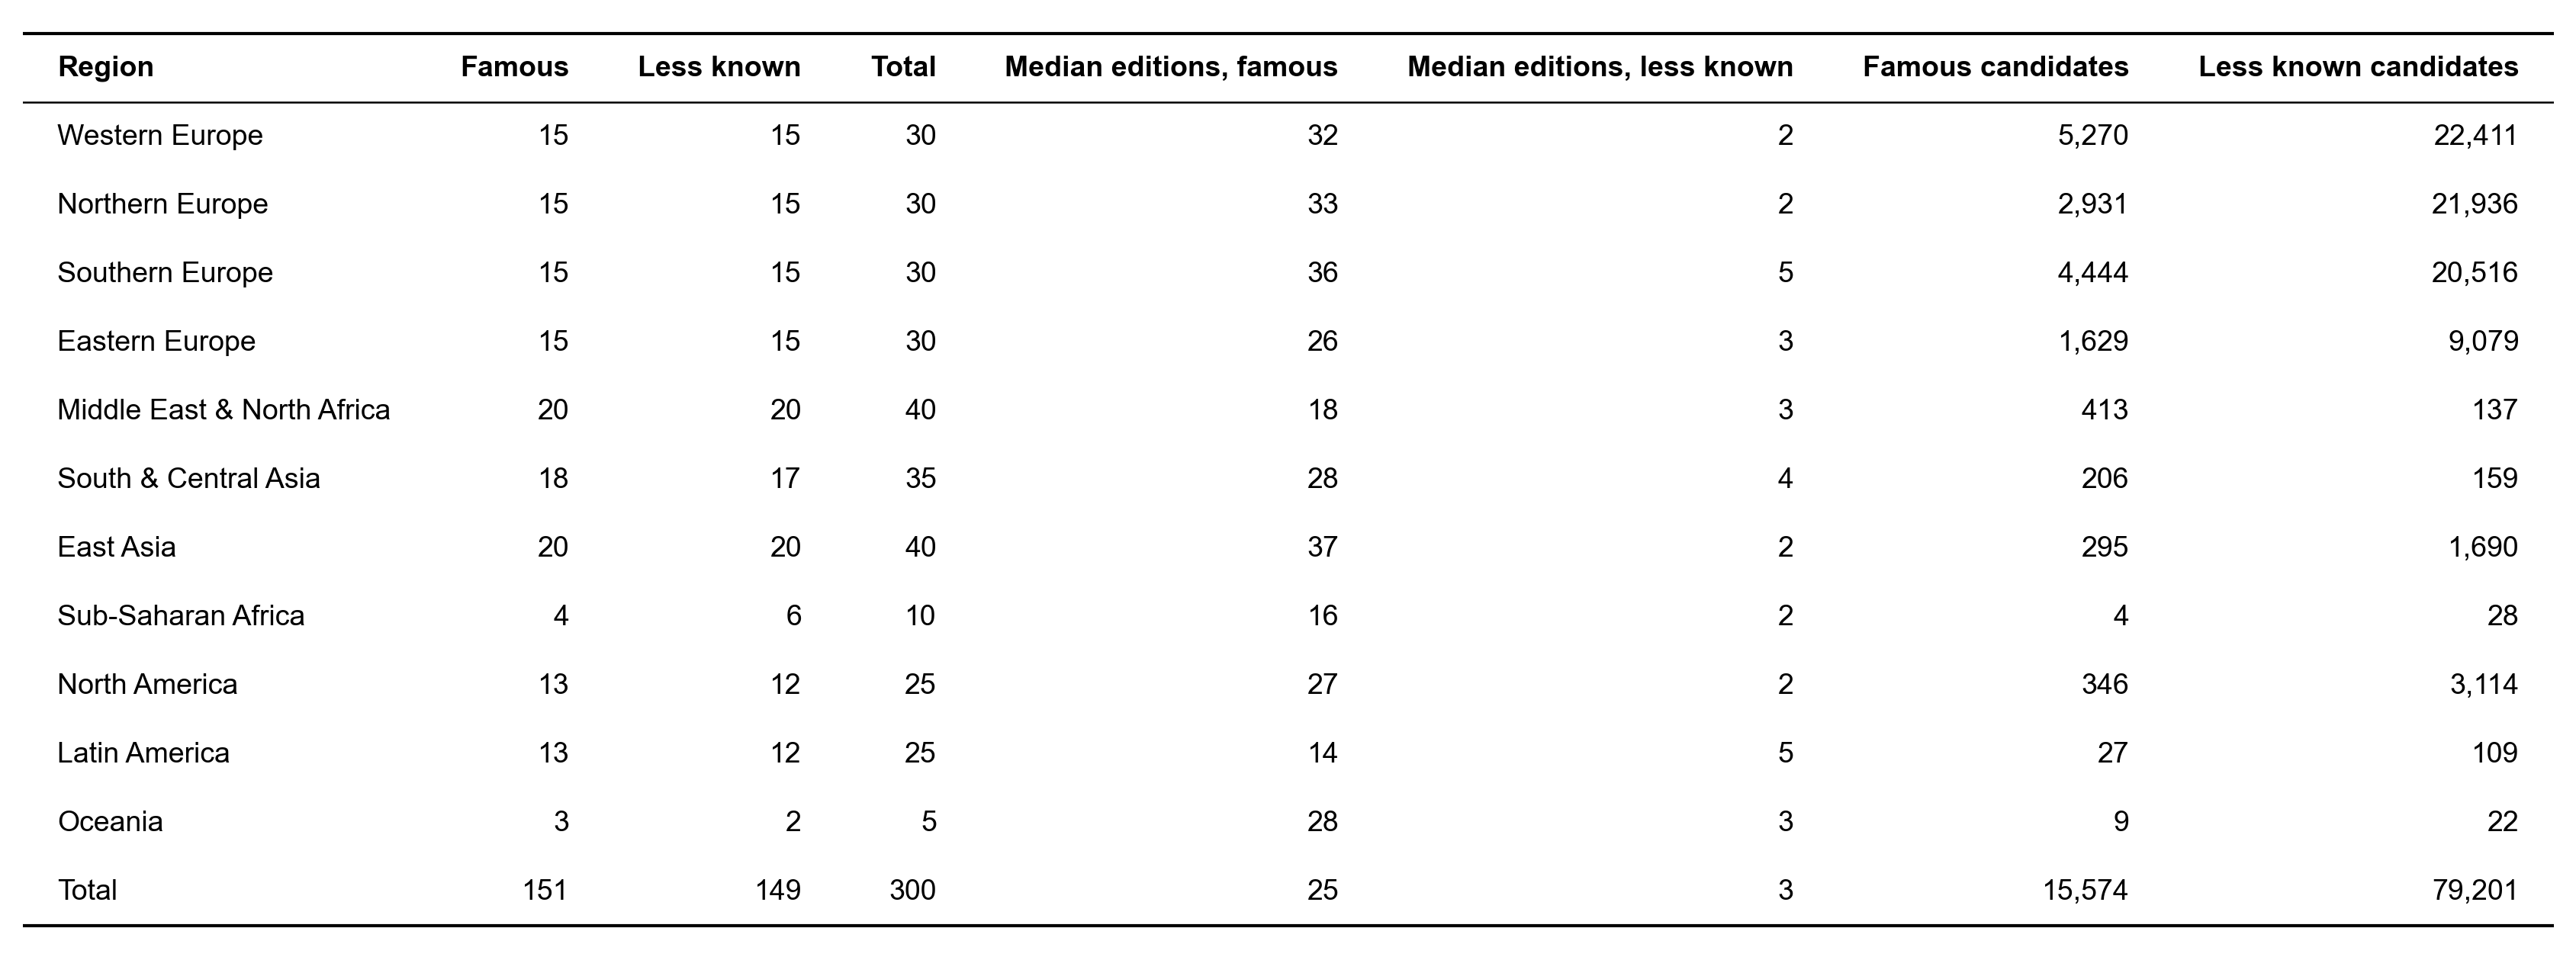

In [10]:
candidates = sample.filter(pl.col("three_stages")).unique("qid")
notability = (benchmark.group_by("region", "notability").agg(benchmark=pl.len(), editions=pl.col("wikipedia_editions").median())
              .join(candidates.group_by("region", "notability").agg(candidates=pl.len()), on=["region", "notability"])
              .pivot(on="notability", index="region", values=["benchmark", "editions", "candidates"]).fill_null(0)
              .with_columns(pl.col("region").replace_strict({r: i for i, r in enumerate(REGION_ORDER)}).alias("order")).sort("order"))
notability = notability.select(
    pl.col("region").alias("Region"),
    pl.col("benchmark_famous").alias("Famous"), pl.col("benchmark_less known").alias("Less known"),
    (pl.col("benchmark_famous") + pl.col("benchmark_less known")).alias("Total"),
    pl.col("editions_famous").alias("Median editions, famous"), pl.col("editions_less known").alias("Median editions, less known"),
    pl.col("candidates_famous").alias("Famous candidates"), pl.col("candidates_less known").alias("Less known candidates"))
totals = pl.DataFrame([{"Region": "Total", "Famous": notability["Famous"].sum(), "Less known": notability["Less known"].sum(), "Total": notability["Total"].sum(),
                        "Median editions, famous": benchmark.filter(pl.col("notability") == "famous")["wikipedia_editions"].median(),
                        "Median editions, less known": benchmark.filter(pl.col("notability") == "less known")["wikipedia_editions"].median(),
                        "Famous candidates": notability["Famous candidates"].sum(), "Less known candidates": notability["Less known candidates"].sum()}])
show_table(pl.concat([notability, totals], how="vertical_relaxed"), decimals=0, font_size=9)

## Century fill

Individuals added by `building_scripts/benchmark_fill.py` so that every region and century of birth (Cultura birth year) has at least 3 individuals, or all its candidates with the three life stages and a readable biography when there are fewer. Number of individuals per region and century after the fill; a dash is a century with no candidate in the region.

shape: (2, 2)
┌──────────────┬───────┐
│ draw         ┆ count │
│ ---          ┆ ---   │
│ str          ┆ u32   │
╞══════════════╪═══════╡
│ quota        ┆ 300   │
│ century fill ┆ 249   │
└──────────────┴───────┘


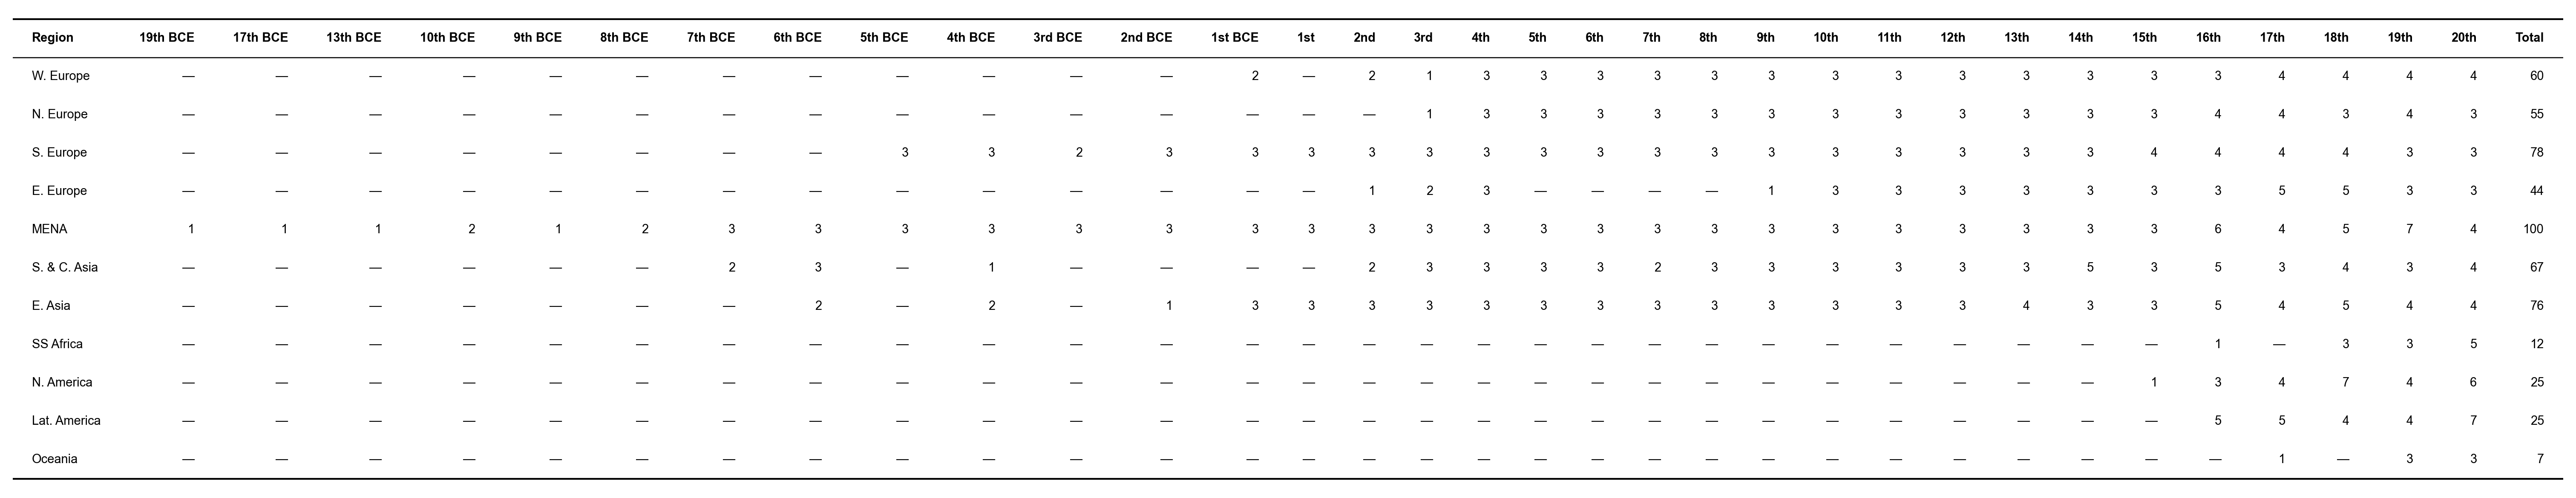

In [11]:
full = pl.read_csv(ROOT / "scripts" / "5-annotations" / "benchmark" / "benchmark_cultura.tsv", separator="\t").with_columns(century=pl.col("cultura_birth_date_year") // 100 + 1)
print(full["draw"].value_counts())


def century_name(century):
    number = century if century > 0 else abs(century) + 1
    suffix = "th" if 10 <= number % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(number % 10, "th")
    return f"{number}{suffix}" + (" BCE" if century <= 0 else "")


centuries = full["century"].unique().sort().to_list()
fill = (full.group_by("claude_estimated_region", "century").len()
        .with_columns(pl.col("century").map_elements(century_name, return_dtype=pl.String))
        .pivot(on="century", index="claude_estimated_region", values="len")
        .with_columns(pl.col("claude_estimated_region").replace_strict({r: i for i, r in enumerate(REGION_ORDER)}).alias("order")).sort("order"))
fill = fill.select(pl.col("claude_estimated_region").map_elements(lambda region: SHORT.get(region, region), return_dtype=pl.String).alias("Region"),
                   *[century_name(century) for century in centuries if century_name(century) in fill.columns])
show_table(fill.with_columns(Total=pl.sum_horizontal(pl.exclude("Region"))), font_size=7)

## Extraction prompt

Prompt given to the Claude agents that read each biography and write the pre-active, active and post-active places (`scripts/5-annotations/prompts/biography_life_stage_extraction.md`). The stages follow the Cultura life stages: pre-active life (birth to start of active life), active life (start to end of active life) and post-active life (end of active life to death).

In [12]:
from IPython.display import Markdown

prompt = (ROOT / "scripts" / "5-annotations" / "prompts" / "biography_life_stage_extraction.md").read_text()
Markdown(prompt.split("---", 1)[1])



You are extracting structured data from historians' biographies for a validation benchmark (Nature Scientific Data paper, repo /Users/charlesdedampierre/Desktop/Rsearch Folder/cultura/cultura_database). Work only from the biography texts; do NOT open any database, parquet, TSV or Cultura file (the comparison must be blind). Do not use the web.

Your individuals (QIDs): {QIDS}
Each text is at scripts/5-annotations/benchmark/benchmark300/texts/{QID}.txt (header gives the name, dictionary and URL). Some are very long (Stanford Encyclopedia of Philosophy entries): read the opening and the life/biography section (use grep for place names, "born", "died", "Life", etc.) rather than the whole entry.

The life of each individual is split into three stages around the active life. The active life runs from the first to the last work, office or professional activity the individual is known for (first publication, first artwork, first post, first reign or command... up to the last one).
- pre_active: from birth to the start of the active life. Where the individual was born, grew up, was educated and trained, before the first work or office.
- active: from the start to the end of the active life. Where the individual worked, held offices, created or published their works (several places allowed).
- post_active: from the end of the active life to death. Where the individual lived after the last work or office (retirement, exile, last residence) and where they died. If the individual was active until death, give the place where they died.

For each individual and each stage, write the most granular place the biography gives (a city, a region...). If the text says nothing usable for a stage, set that stage to null. Do not use outside knowledge to invent places the text does not mention; you may use your knowledge only to give coordinates.

Output format: the format of scripts/5-annotations/biography_examples/claude_extraction.json (read it first as the reference), with the stage keys renamed. Per QID: {"dictionary": <dictionary name from the header>, "pre_active": {...}|null, "active": {...}|null, "post_active": {...}|null}. Each stage object has:
- "place": the place(s) in English, separated by "; "
- "written": the place as written in the text (short, original language)
- "written_en": English translation of "written" (identical if the text is English)
- "verbatim": list of word-for-word extracts from the text supporting the answer. They MUST be exact substrings of the text file (copy-paste, same spelling, accents and spacing); keep each under ~300 characters.
- "verbatim_en": same list translated to English, same length and order (identical if English)
- "confidence": "high" | "medium" | "low"
- "reasoning": one short sentence
- "points": list of [place name, longitude, latitude] for each place (decimal degrees, your best estimate of the place's location)

Write the result as one JSON object (QID -> entry) to scripts/5-annotations/benchmark/benchmark300/extraction_life_stages/agent_{N}.json (ensure_ascii false, indent 2). Then check it with Python (.venv/bin/python): valid JSON, all your QIDs present, keys pre_active / active / post_active, verbatim and verbatim_en same length, and every verbatim string found in its text file (report and fix any that are not). Reply with a short summary: how many stages filled vs null, and any verbatim you could not match.
